# Practical 6 - Image Smoothing

Aim: Smooth an image using averaging, weighted and Gaussian filters with different padding methods.

Name: Navjot Singh
Roll No: 2025010071


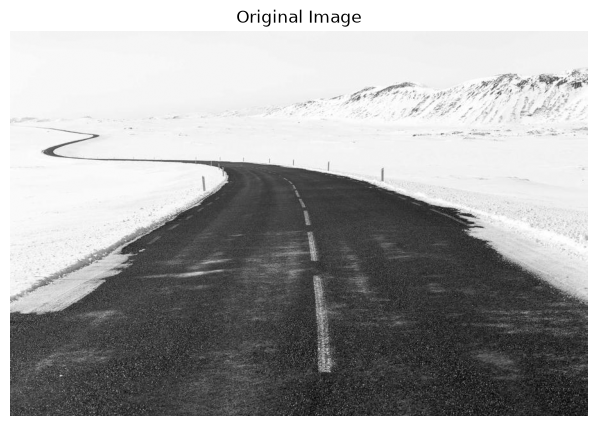

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

print("Name: Navjot Singh")
print("Roll No: 2025010071")

img = cv2.imread("images/navjot_d.jpg", cv2.IMREAD_GRAYSCALE)

size = 5
sigma = 1.5

plt.figure(figsize=(8, 5))
plt.imshow(img, cmap="gray")
plt.title("Original Image")
plt.axis("off")
plt.show()

In [2]:
# averaging filter with zero padding
kernel_avg = np.ones((size, size), np.float32) / (size * size)
avg_filter = cv2.filter2D(img, -1, kernel_avg, borderType=cv2.BORDER_CONSTANT)

In [3]:
# weighted kernel h(x,y) = max(|x|,|y|)
center = size // 2
kernel_weighted = np.zeros((size, size), np.float32)

for i in range(size):
    for j in range(size):
        kernel_weighted[i, j] = max(abs(i - center), abs(j - center))

kernel_weighted = kernel_weighted / kernel_weighted.sum()
weighted_filter = cv2.filter2D(img, -1, kernel_weighted, borderType=cv2.BORDER_REPLICATE)

print("Weighted kernel:")
print(kernel_weighted)

Weighted kernel:
[[0.05  0.05  0.05  0.05  0.05 ]
 [0.05  0.025 0.025 0.025 0.05 ]
 [0.05  0.025 0.    0.025 0.05 ]
 [0.05  0.025 0.025 0.025 0.05 ]
 [0.05  0.05  0.05  0.05  0.05 ]]


In [4]:
# gaussian filter
gaussian_filter = cv2.GaussianBlur(img, (size, size), sigma)

Filter size: 5
Gaussian sigma: 1.5
Padding: zero for averaging, replicate for weighted, reflect for Gaussian


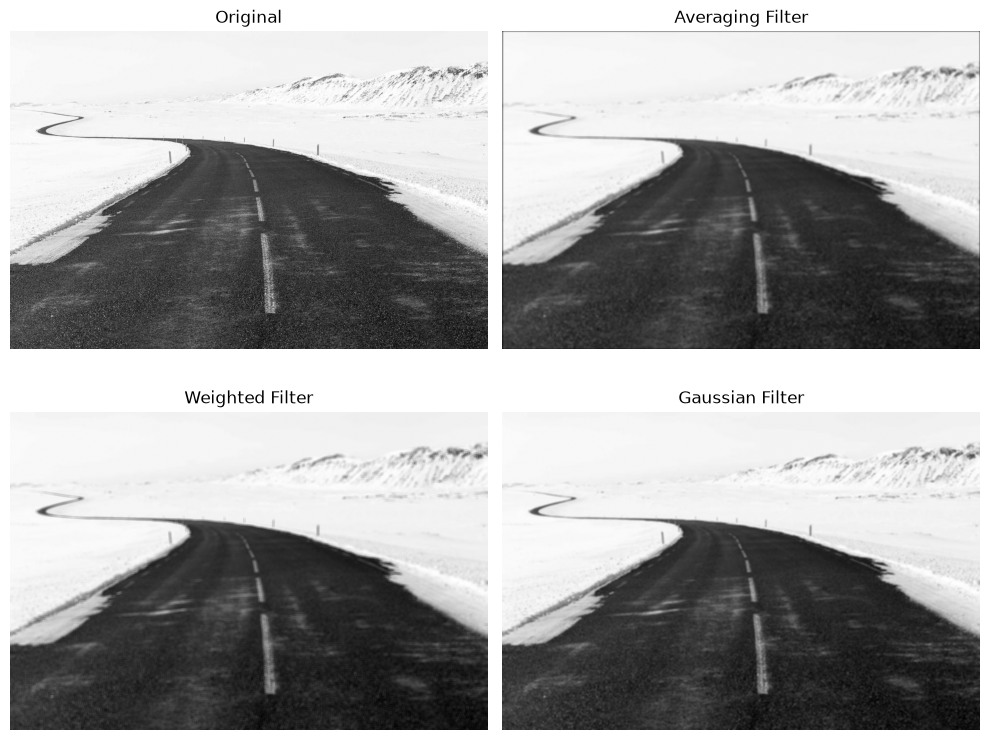

In [5]:
print("Filter size:", size)
print("Gaussian sigma:", sigma)
print("Padding: zero for averaging, replicate for weighted, reflect for Gaussian")

titles = ["Original", "Averaging Filter", "Weighted Filter", "Gaussian Filter"]
images = [img, avg_filter, weighted_filter, gaussian_filter]

plt.figure(figsize=(10, 8))
for i in range(4):
    plt.subplot(2, 2, i + 1)
    plt.imshow(images[i], cmap="gray")
    plt.title(titles[i])
    plt.axis("off")

plt.tight_layout()
plt.show()